In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from databricks import sql

load_dotenv()

# Parâmetro do pipeline — "store" ou "warehouse".
# Trocar aqui e reexecutar o notebook do início é o que gera a segunda passagem (Centro de Distribuição),
# sem duplicar nenhuma lógica de query.
LOCATION_TYPE = "warehouse"

connection = sql.connect(
    server_hostname=os.environ["DATABRICKS_HOST"],
    http_path=os.environ["DATABRICKS_HTTP_PATH"],
    access_token=os.environ["DATABRICKS_TOKEN"],
    catalog=os.environ.get("DATABRICKS_CATALOG", "dev"),
    schema="gold",
)

def run_query(query: str) -> pd.DataFrame:
    """Executa uma query no SQL Warehouse e retorna um DataFrame pandas."""
    with connection.cursor() as cursor:
        cursor.execute(query)
        if cursor.description is None:
            return pd.DataFrame()
        rows = cursor.fetchall()
        columns = [desc[0] for desc in cursor.description]
        return pd.DataFrame(rows, columns=columns)

In [10]:
run_query(f"""
CREATE OR REPLACE TEMP VIEW eda_base AS
SELECT
    f.product_variant_id,
    p.category_name,
    f.location_id,
    c.ano,
    c.mes,
    DATE(CONCAT(c.ano, '-', LPAD(c.mes, 2, '0'), '-01')) AS mes_ref,
    SUM(f.quantity)           AS quantidade_mes,
    SUM(f.valor_liquido_item) AS valor_liquido_mes
FROM fct_orders f
JOIN dim_produtos  p ON f.product_variant_id = p.product_variant_id
JOIN dim_locations l ON f.location_id        = l.location_id
JOIN dim_calendar  c ON f.placed_at_key      = c.date_key
WHERE l.location_type = '{LOCATION_TYPE}'
GROUP BY f.product_variant_id, p.category_name, f.location_id, c.ano, c.mes
""")

run_query(f"""
CREATE OR REPLACE TEMP VIEW eda_historico AS
WITH janela_combinacao AS (
    SELECT
        product_variant_id,
        location_id,
        MIN(mes_ref)              AS min_mes_combinacao,
        MAX(mes_ref)              AS max_mes_combinacao,
        COUNT(DISTINCT mes_ref)   AS meses_com_venda
    FROM eda_base
    GROUP BY product_variant_id, location_id
)
SELECT
    product_variant_id,
    location_id,
    meses_com_venda,
    MONTHS_BETWEEN(max_mes_combinacao, min_mes_combinacao) + 1 AS meses_de_vida,
    ROUND(meses_com_venda / (MONTHS_BETWEEN(max_mes_combinacao, min_mes_combinacao) + 1), 3) AS pct_cobertura
FROM janela_combinacao
""")

df_hist = run_query("SELECT * FROM eda_historico")

In [11]:
print(df_hist['meses_com_venda'].describe(percentiles=[.1, .5, .75, .9, .95, .99]))
print(df_hist['pct_cobertura'].describe(percentiles=[.1, .5, .75, .9, .95, .99]))

count    3027.000000
mean       20.801123
std         3.832078
min         8.000000
10%        16.000000
50%        21.000000
75%        23.000000
90%        26.000000
95%        27.000000
99%        30.000000
max        34.000000
Name: meses_com_venda, dtype: float64
count    3027.000000
mean        0.265770
std         0.047183
min         0.130000
10%         0.205000
50%         0.265000
75%         0.298000
90%         0.328000
95%         0.345700
99%         0.378000
max         0.446000
Name: pct_cobertura, dtype: float64


In [ ]:
p_meses = df_hist['meses_com_venda'].quantile([.10, .50, .75, .90]).round().astype(int)
p_cobertura = df_hist['pct_cobertura'].quantile([.10, .50, .75, .90]).round(2)

candidatos_limiar = [
    {"min_meses": int(p_meses[.10]), "min_pct_cobertura": float(p_cobertura[.10])},  # frouxo — a maioria passaria
    {"min_meses": int(p_meses[.50]), "min_pct_cobertura": float(p_cobertura[.50])},  # mediano
    {"min_meses": int(p_meses[.75]), "min_pct_cobertura": float(p_cobertura[.75])},  # moderadamente rígido
    {"min_meses": int(p_meses[.90]), "min_pct_cobertura": float(p_cobertura[.90])},  # rígido — só as combinações mais consistentes
]
print(candidatos_limiar)

resultados = []
for candidato in candidatos_limiar:
    madura = (
        (df_hist['meses_com_venda'] >= candidato['min_meses']) &
        (df_hist['pct_cobertura']   >= candidato['min_pct_cobertura'])
    )
    resultados.append({
        **candidato,
        "pct_combinacoes_maduras": round(madura.mean(), 3),
        "n_combinacoes_maduras": int(madura.sum()),
        "n_combinacoes_total": len(df_hist),
    })

df_candidatos_limiar = pd.DataFrame(resultados)
print(df_candidatos_limiar)

[{'min_meses': 16, 'min_pct_cobertura': 0.2}, {'min_meses': 21, 'min_pct_cobertura': 0.26}, {'min_meses': 23, 'min_pct_cobertura': 0.3}, {'min_meses': 26, 'min_pct_cobertura': 0.33}]
   min_meses  min_pct_cobertura  pct_combinacoes_maduras  \
0         16               0.20                    0.900   
1         21               0.26                    0.468   
2         23               0.30                    0.209   
3         26               0.33                    0.067   

   n_combinacoes_maduras  n_combinacoes_total  
0                   2725                 3027  
1                   1416                 3027  
2                    632                 3027  
3                    203                 3027  


In [13]:
df_vol = run_query("""
    SELECT product_variant_id, location_id,
           SUM(quantidade_mes) AS quantidade_total
    FROM eda_base
    GROUP BY product_variant_id, location_id
""")

volume_total = df_vol['quantidade_total'].sum()
resultados_volume = []
for candidato in candidatos_limiar:
    maduras = df_hist[
        (df_hist['meses_com_venda'] >= candidato['min_meses']) &
        (df_hist['pct_cobertura']   >= candidato['min_pct_cobertura'])
    ][['product_variant_id', 'location_id']]
    volume_coberto = df_vol.merge(maduras, on=['product_variant_id', 'location_id'])['quantidade_total'].sum()
    resultados_volume.append({**candidato, "pct_volume_coberto": round(volume_coberto / volume_total, 3)})

print(pd.DataFrame(resultados_volume))

   min_meses  min_pct_cobertura  pct_volume_coberto
0         16               0.20               0.931
1         21               0.26               0.539
2         23               0.30               0.260
3         26               0.33               0.090


In [ ]:
# Limiar oficial — DECIDIDO pelo time em 03/09, com base em df_candidatos_limiar e df_cobertura_volume:
# Candidatos mais rígidos (21/0.26 em diante) derrubavam volume e combinações quase na mesma proporção
# (ex.: 21/0.26 cobria só 54,2% da quantidade total) — ou seja, não há "corte barato" nesta base, cortar
# combinações corta demanda real na mesma medida. Escolhido o candidato mais frouxo da grade por ser o
# único que preserva a grande maioria tanto de combinações (90,1%) quanto de volume (93,1%), essencial
# para a pergunta de negócio 1 (previsão "por produto e por loja").
#
# Ressalva registrada para o Model Card: um limiar de 20% de cobertura aceita séries com demanda
# intermitente (venda em só 1 a cada 5 meses de vida) — padrão historicamente mais difícil para os 4
# modelos de regressão capturarem bem. É limitação conhecida a monitorar no backtesting do Bloco B,
# não um problema a resolver aqui.
MIN_MESES_HISTORICO   = 16
MIN_PCT_COBERTURA     = 0.20

assert MIN_MESES_HISTORICO is not None and MIN_PCT_COBERTURA is not None, \
    "Definir o limiar oficial antes de continuar — ver tabela da Célula 2."

df_hist['historico_suficiente'] = (
    (df_hist['meses_com_venda'] >= MIN_MESES_HISTORICO) &
    (df_hist['pct_cobertura']   >= MIN_PCT_COBERTURA)
)

print(f"Combinações maduras: {df_hist['historico_suficiente'].sum()} de {len(df_hist)} "
      f"({df_hist['historico_suficiente'].mean():.1%})")

Combinações maduras: 2725 de 3027 (90.0%)


periodo             alta_temporada  resto_do_ano  indice_sazonalidade
product_variant_id                                                   
3                        15.157895      6.777778             2.236411
541                      11.529412      5.250000             2.196078
763                      12.761905      6.107143             2.089669
436                      10.478261      5.058824             2.071284
123                      11.380952      5.520000             2.061767


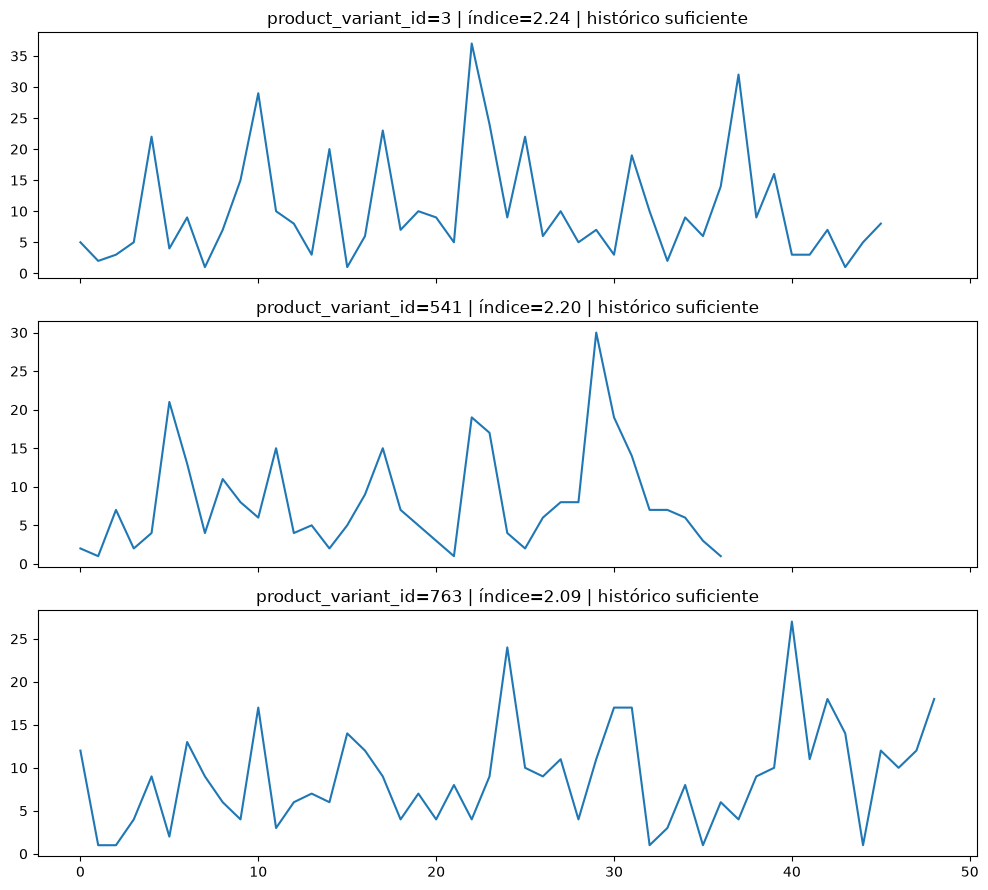

In [ ]:
variantes_maduras = set(df_hist.loc[df_hist['historico_suficiente'], 'product_variant_id'])

df_variant_month = run_query("""
    SELECT product_variant_id, ano, mes, SUM(quantidade_mes) AS quantidade
    FROM eda_base
    GROUP BY product_variant_id, ano, mes
""")
df_variant_month = df_variant_month[df_variant_month.product_variant_id.isin(variantes_maduras)]

MESES_ALTA_TEMPORADA = [12, 1, 2, 3]
df_variant_month['periodo'] = df_variant_month['mes'].apply(
    lambda m: 'alta_temporada' if m in MESES_ALTA_TEMPORADA else 'resto_do_ano'
)

medias = (
    df_variant_month
    .groupby(['product_variant_id', 'periodo'])['quantidade']
    .mean()
    .unstack('periodo')
    .dropna()
)
medias = medias[medias['resto_do_ano'] > 0]
medias['indice_sazonalidade'] = medias['alta_temporada'] / medias['resto_do_ano']

candidatos_finais = medias.sort_values('indice_sazonalidade', ascending=False).head(5)
print(candidatos_finais)

# Confirmação visual das top 3 — evita escolher pelo número isolado
top3 = candidatos_finais.head(3).index.tolist()
fig, axes = plt.subplots(len(top3), 1, figsize=(10, 3*len(top3)), sharex=True)
for ax, variant_id in zip(axes, top3):
    sub = df_variant_month[df_variant_month.product_variant_id == variant_id].sort_values(['ano', 'mes'])
    ax.plot(range(len(sub)), sub['quantidade'])
    ax.set_title(f"product_variant_id={variant_id} | índice={candidatos_finais.loc[variant_id, 'indice_sazonalidade']:.2f} | histórico suficiente")
plt.tight_layout()
plt.show()

In [16]:
connection.close()